# Modelo 1 — Etapa 3: Treinamento, Avaliação Multicritério e Explicabilidade
## Metodologia CRISP-DM: Fases 4, 5 e 6

Este notebook consolida as etapas de modelagem, avaliação e exportação do **Modelo 1** para as Portas de Plataforma (PSD) da Linha 4-Amarela.

---

### Fase 4: Modelagem (Modeling)
* Treinamento do Ensemble Híbrido ponderado combinando **XGBoost Classifier** (regularizado com `scale_pos_weight = 9.5`) e **HistGradientBoosting Classifier** (`class_weight = 'balanced'`).

---

### Fase 5: Avaliação (Evaluation)
* **Régua Estrita de Episódios de Alerta e Eventos Reais:** Avaliação causal evento-a-evento na janela $[D+1, D+7]$, eliminando qualquer viés de duplicação de falhas ou esticamento de janela temporal.
* **Explicabilidade Global e Local com SHAP (SHapley Additive exPlanations):** Interpretabilidade física do impacto de cada feature nas predições de risco de quebra.

---

### Fase 6: Implantação (Deployment)
* Serialização do modelo preditivo em arquivo binário `.joblib` em `data/modelos_artefatos/` para integração operacional com dashboards de manutenção.



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, VotingClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score, roc_curve,
    precision_recall_curve, average_precision_score, f1_score, precision_score, recall_score
)
import shap
import joblib
import json
import os
import re
import warnings

warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 120

print("Bibliotecas carregadas com sucesso!")


Bibliotecas carregadas com sucesso!


C:\Users\Inteli\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Modeling: Ingestão dos Datasets de Treino e Teste Cego


In [2]:
p_tr = "../../data/treino_pronto_modelagem_v2.csv"
if not os.path.exists(p_tr): p_tr = "data/treino_pronto_modelagem_v2.csv"
p_te = "../../data/teste_pronto_modelagem_v2.csv"
if not os.path.exists(p_te): p_te = "data/teste_pronto_modelagem_v2.csv"

df_treino = pd.read_csv(p_tr)
df_teste = pd.read_csv(p_te)

target_col = 'target_falha_7d'
cols_ignorar = ['id_ativo', 'data_ref', target_col]
features = [c for c in df_treino.columns if c not in cols_ignorar]

X_train = df_treino[features]
y_train = df_treino[target_col]

X_test = df_teste[features]
y_test = df_teste[target_col]

# Ingestão das Ordens ZM01 Reais do período de teste para a Régua Estrita
p_zm01 = "../../data/Corretiva Emergencial/processados/ZM01_limpa.xlsx"
if not os.path.exists(p_zm01): p_zm01 = "data/Corretiva Emergencial/processados/ZM01_limpa.xlsx"
df_zm01_raw = pd.read_excel(p_zm01)

padrao_sap = re.compile(r'SP04-6-PSD-([A-Z]{3})-(?:PLT|P)(\d+)(?:-PP(\d+))?', re.IGNORECASE)

def extrair_id_sap(loc_str):
    m = padrao_sap.search(str(loc_str))
    if m and m.group(3):
        return f"{m.group(1).upper()}_P{m.group(2)}_PDM{int(m.group(3)):02d}"
    return None

df_zm01_raw['id_ativo'] = df_zm01_raw['local_de_instalacao'].apply(extrair_id_sap)
df_zm01_raw['data_evento'] = pd.to_datetime(df_zm01_raw['inicio_avaria_datetime'], errors='coerce').dt.normalize()

data_min_test = pd.to_datetime(df_teste['data_ref'].min())
data_max_test = pd.to_datetime(df_teste['data_ref'].max())

df_zm01_teste = df_zm01_raw[
    (df_zm01_raw['data_evento'] >= data_min_test) & 
    (df_zm01_raw['data_evento'] <= data_max_test) & 
    (df_zm01_raw['id_ativo'].notna())
][['id_ativo', 'data_evento']].drop_duplicates().sort_values(['id_ativo', 'data_evento']).reset_index(drop=True)

print(f"Features de Modelagem ({len(features)}): {features[:6]}...")
print(f"Treino: {X_train.shape[0]:,} amostras | Teste Cego: {X_test.shape[0]:,} amostras")
print(f"Corretivas ZM01 Reais e Distintas no Teste: {len(df_zm01_teste):,} ocorrências.")



Features de Modelagem (32): ['plataforma_bin', 'faixa_risco_zm01', 'estacao_BUT', 'estacao_FAL', 'estacao_FRA', 'estacao_FRE']...
Treino: 576,496 amostras | Teste Cego: 31,034 amostras
Corretivas ZM01 Reais e Distintas no Teste: 388 ocorrências.


## 2. Modeling: Treinamento do Ensemble Híbrido Otimizado (XGBoost + HistGradientBoosting)


In [3]:
xgb = XGBClassifier(
    n_estimators=350, max_depth=4, learning_rate=0.025,
    min_child_weight=20, subsample=0.80, colsample_bytree=0.80,
    reg_alpha=2.0, reg_lambda=5.0, scale_pos_weight=9.5,
    random_state=42, n_jobs=-1, tree_method='hist', eval_metric='logloss'
)

hgb = HistGradientBoostingClassifier(
    max_iter=250, max_depth=5, learning_rate=0.03,
    min_samples_leaf=30, class_weight='balanced', random_state=42
)

ensemble = VotingClassifier(
    estimators=[('xgb', xgb), ('hgb', hgb)],
    voting='soft',
    weights=[1.5, 1.0]
)

print("Treinando o Ensemble Preditivo...")
ensemble.fit(X_train, y_train)

probs_test = ensemble.predict_proba(X_test)[:, 1]
df_teste['prob_falha'] = probs_test
df_teste['data_ref'] = pd.to_datetime(df_teste['data_ref'])
df_teste['semana'] = df_teste['data_ref'].dt.isocalendar().week

roc_auc = roc_auc_score(y_test, probs_test)
pr_auc = average_precision_score(y_test, probs_test)

print("Treinamento concluído com sucesso!")
print(f"   -> ROC-AUC Score Global: {roc_auc:.4f}")
print(f"   -> PR-AUC (Average Precision): {pr_auc:.4f}")



Treinando o Ensemble Preditivo...


  File "C:\Users\Inteli\AppData\Local\Programs\Python\Python314\Lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
  File "C:\Users\Inteli\AppData\Local\Programs\Python\Python314\Lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\Inteli\AppData\Local\Programs\Python\Python314\Lib\subprocess.py", line 555, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Inteli\AppData\Local\Programs\Python\Python314\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
        

Treinamento concluído com sucesso!
   -> ROC-AUC Score Global: 0.5212
   -> PR-AUC (Average Precision): 0.0914


## 3. Evaluation: Avaliação na Régua Estrita por Episódios de Alerta e Eventos Reais


In [4]:
def avaliar_por_episodio(df_pred, df_zm01_reais, threshold=0.50):
    alertas = df_pred[df_pred['prob_falha'] >= threshold].copy().sort_values(['id_ativo', 'data_ref'])
    if len(alertas) == 0:
        return {'registros_alertados': 0, 'precisao': 0, 'recall': 0, 'f1': 0, 'episodios': 0, 'acertos': 0, 'quebras_evitadas': 0, 'quebras_totais': len(df_zm01_reais)}
        
    alertas['gap_dias'] = alertas.groupby('id_ativo')['data_ref'].diff().dt.days
    alertas['novo_episodio'] = (alertas['gap_dias'] > 2) | (alertas['gap_dias'].isna())
    alertas['episodio_id'] = alertas.groupby('id_ativo')['novo_episodio'].cumsum()
    
    episodios = alertas.groupby(['id_ativo', 'episodio_id']).agg(
        data_inicio=('data_ref', 'min'),
        max_prob=('prob_falha', 'max')
    ).reset_index()
    
    acertos_episodios = 0
    for _, ep in episodios.iterrows():
        ativo = ep['id_ativo']
        d_ini = ep['data_inicio']
        d_fim = d_ini + pd.Timedelta(days=7)
        teve_quebra = ((df_zm01_reais['id_ativo'] == ativo) & 
                       (df_zm01_reais['data_evento'] > d_ini) & 
                       (df_zm01_reais['data_evento'] <= d_fim)).any()
        if teve_quebra:
            acertos_episodios += 1
            
    total_episodios = len(episodios)
    precisao = acertos_episodios / total_episodios if total_episodios > 0 else 0
    
    quebras_evitadas = 0
    for _, qb in df_zm01_reais.iterrows():
        ativo = qb['id_ativo']
        t_quebra = qb['data_evento']
        t_ini = t_quebra - pd.Timedelta(days=7)
        houve_alerta = ((alertas['id_ativo'] == ativo) & 
                        (alertas['data_ref'] >= t_ini) & 
                        (alertas['data_ref'] < t_quebra)).any()
        if houve_alerta:
            quebras_evitadas += 1
            
    total_quebras = len(df_zm01_reais)
    recall = quebras_evitadas / total_quebras if total_quebras > 0 else 0
    f1 = 2 * precisao * recall / (precisao + recall + 1e-10)
    
    return {
        'registros_alertados': len(alertas),
        'precisao': precisao,
        'recall': recall,
        'f1': f1,
        'episodios': total_episodios,
        'acertos': acertos_episodios,
        'quebras_evitadas': quebras_evitadas,
        'quebras_totais': total_quebras
    }

def avaliar_limiares(df_pred, df_eventos, limiares):
    base = df_pred.copy().reset_index(drop=True)
    if base[['id_ativo', 'data_ref', 'prob_falha']].isna().any().any():
        raise ValueError('Ativo, data e probabilidade devem estar preenchidos.')
    if not base['prob_falha'].between(0, 1).all():
        raise ValueError('Probabilidades devem ser finitas e estar entre 0 e 1.')
    base['data_ref'] = pd.to_datetime(base['data_ref'], errors='raise')
    if base.duplicated(['id_ativo', 'data_ref']).any():
        raise ValueError('A base deve ter apenas um registro por ativo e data.')
    cortes = np.asarray(list(limiares), dtype=float)
    if cortes.size == 0 or not np.isfinite(cortes).all() or ((cortes < 0) | (cortes > 1)).any():
        raise ValueError('Informe limiares finitos entre 0 e 1.')
    resultados = []
    anteriores = np.ones(len(base), dtype=bool)
    for th in sorted(set(cortes)):
        selecionados = base['prob_falha'].to_numpy() >= th
        if (selecionados & ~anteriores).any():
            raise AssertionError('O corte maior selecionou novos registros.')
        res = avaliar_por_episodio(base, df_eventos, threshold=th)
        if res['registros_alertados'] != int(selecionados.sum()):
            raise AssertionError('Contagem diverge do filtro de probabilidade.')
        resultados.append({'limiar': th, **res})
        anteriores = selecionados
    tabela = pd.DataFrame(resultados)
    if (tabela['registros_alertados'].diff().dropna() > 0).any():
        raise AssertionError('Volume de registros deve ser nao crescente.')
    if (tabela['quebras_evitadas'].diff().dropna() > 0).any():
        raise AssertionError('Falhas com alerta previo devem ser nao crescentes.')
    return tabela.rename(columns={'quebras_evitadas': 'falhas_com_alerta_previo'})

tabela_limiares = avaliar_limiares(df_teste, df_zm01_teste, [0.45, 0.48, 0.50, 0.52, 0.55, 0.60, 0.65])
print('AUDITORIA OK: registros e falhas com alerta previo nao crescentes.')
print('Registros = porta-dia acima do corte. Episodios = alertas agrupados por ativo, com intervalo de ate 2 dias.')
print('Episodios podem aumentar por fragmentacao; nao representam chamados efetivamente abertos.')
print('Precisao por episodio; recall por evento real. F1 combina unidades distintas e e apenas descritivo.')
print(tabela_limiares.to_string(index=False, float_format=lambda valor: f'{valor:.4f}'))



AUDITORIA OK: registros e falhas com alerta previo nao crescentes.
Registros = porta-dia acima do corte. Episodios = alertas agrupados por ativo, com intervalo de ate 2 dias.
Episodios podem aumentar por fragmentacao; nao representam chamados efetivamente abertos.
Precisao por episodio; recall por evento real. F1 combina unidades distintas e e apenas descritivo.
 limiar  registros_alertados  precisao  recall     f1  episodios  acertos  falhas_com_alerta_previo  quebras_totais
 0.4500                29530    0.0934  0.9768 0.1705        760       71                       379             388
 0.4800                20045    0.0880  0.8634 0.1597       1466      129                       335             388
 0.5000                 6380    0.1081  0.5309 0.1796       1166      126                       206             388
 0.5200                 1115    0.1492  0.2526 0.1876        449       67                        98             388
 0.5500                  406    0.1398  0.1314 0.1355  

## 4. Evaluation: Explicabilidade e Importância das Features via SHAP Values


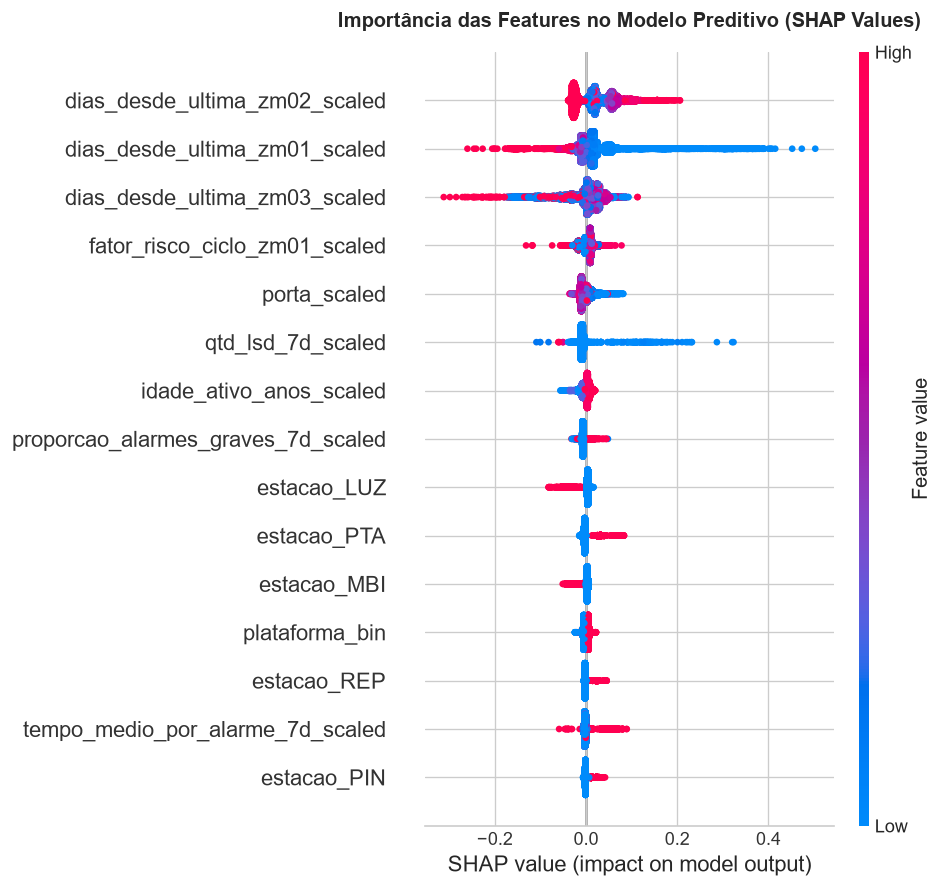

In [5]:
# Extração do modelo XGBoost treinado dentro do VotingClassifier
xgb_fitted = ensemble.named_estimators_['xgb']

explainer = shap.TreeExplainer(xgb_fitted)
shap_values = explainer.shap_values(X_test)

plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_test, feature_names=features, show=False, max_display=15)
plt.title('Importância das Features no Modelo Preditivo (SHAP Values)', fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()



## 5. Deployment: Serialização e Persistência do Modelo Oficial


In [6]:
p_dir_art = "../../data/modelos_artefatos"
if not os.path.exists("../../data"): p_dir_art = "data/modelos_artefatos"
os.makedirs(p_dir_art, exist_ok=True)

caminho_modelo = f"{p_dir_art}/modelo_ensemble_otimizado.joblib"
joblib.dump(ensemble, caminho_modelo)
tabela_limiares.to_csv(f'{p_dir_art}/modelo_1_limiares.csv', index=False)
print(f"Modelo Ensemble Oficial salvo com sucesso em: {caminho_modelo}")



Modelo Ensemble Oficial salvo com sucesso em: ../../data/modelos_artefatos/modelo_ensemble_otimizado.joblib
